# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [1]:
import os
from datetime import datetime

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v2
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
# %aimport lassi.pipeline
%aimport lassi.pipeline_v2
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "stu-matrix-rotate"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = app_folder_name + "-cuda_main"  # "lid-driven-cavity-cuda_main"  # "jacobi-cuda_main"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2
    use_self_prompting = False  # True or False -- NOT USED IN v2
    use_context_summaries_only = True  # True or False
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = ["30000", "100"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    model = "gpto3mini"  # (max token = 200000)
    model_coder = "gpt4olatest"  # (max token = 128000)
    model_judge = "gpto3mini"  # (max token = 200000)

    # -- FROM OLLAMA
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini", "gpto3mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_" + llm_source + "_ee_hecb_selfcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 04-02-2025_t07_27_00
Application: stu-matrix-rotate

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto3mini
Model coder: gpt4olatest
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True


***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****


----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
c

Waiting for the system to settle down for 1 seconds...: 100%|█████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/stu-matrix-rotate
Execute command: ['./stu-matrix-rotate-cuda_main', '30000', '100']

Average kernel execution time: 0.063324 (s)
GPU power data has been written to source_CUDA_gpu_net_power_results.csv


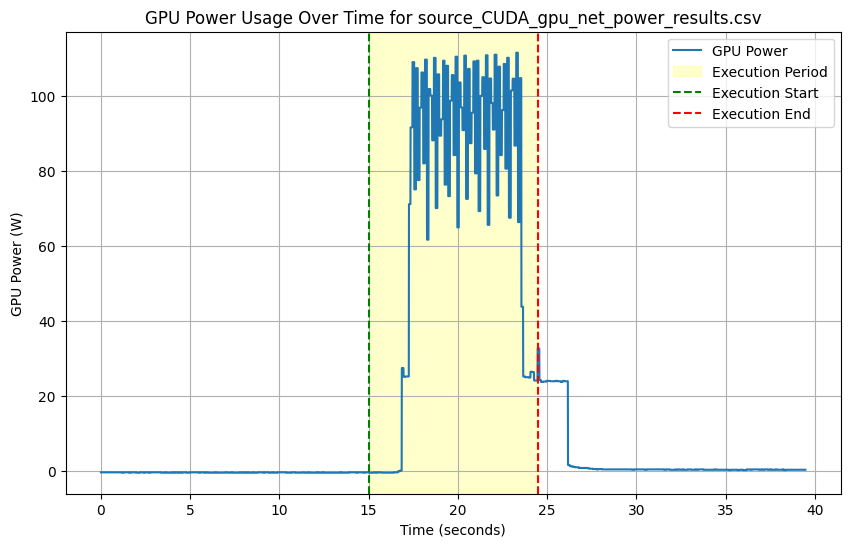

Start time: 15.001 -- End time: 24.472
Total GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000173 kWh
  0.1734 Wh
  624.32 J
Average GPU power: 65.92 W
Total Energy During Exe Runtime:   624.32 J
Code execution duration: 9.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.56 W, P0



Measure system idle power...
Duration for idle time measurement: 9.47
GPU power data has been written to idle__gpu_net_power_results.csv


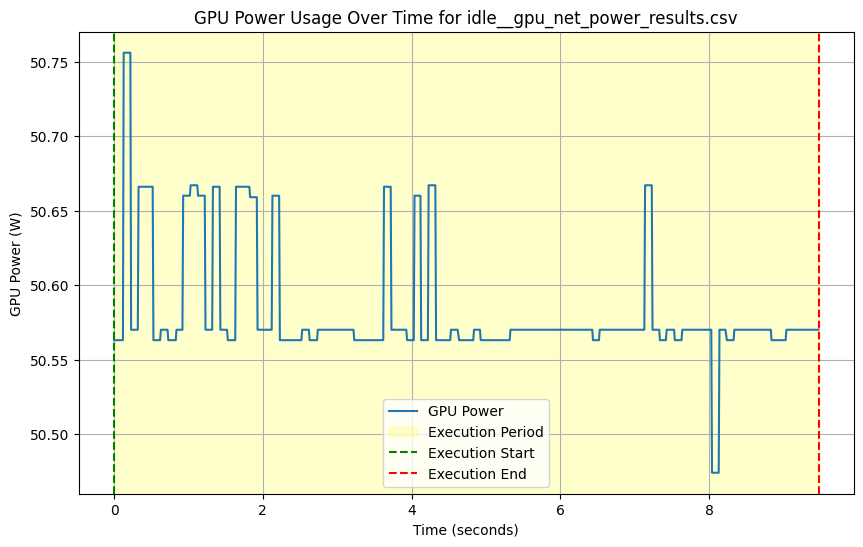

Start time: 0 -- End time: 9.472
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000133 kWh
  0.1332 Wh
  479.54 J
Average GPU power: 50.58 W
Total Energy During Exe Runtime:   479.54 J
Code execution duration: 9.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------


----- STARTING FIRST STAGE: ZERO-SHOT BASE LLM REFACTORING -----


----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.57 W, P0


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 24): 


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided C



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.38 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.000002 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


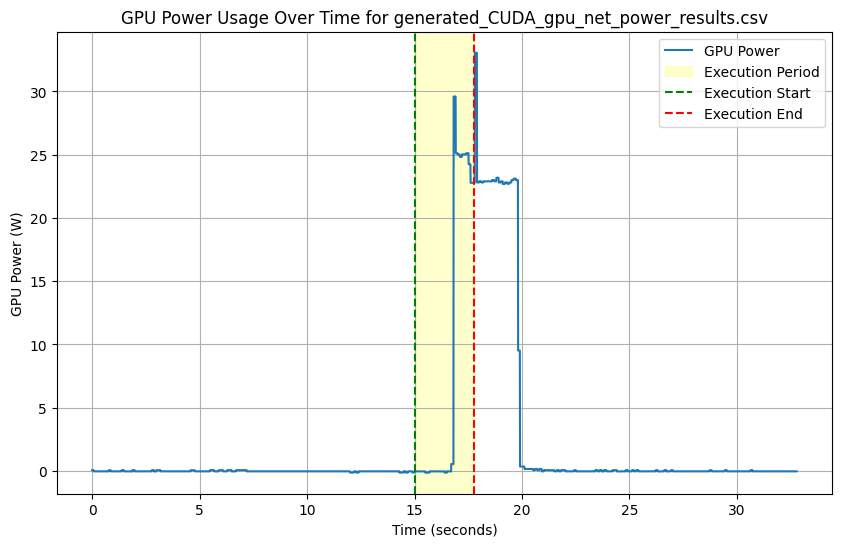

Start time: 15.001 -- End time: 17.781
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000007 kWh
  0.0068 Wh
  24.41 J
Average GPU power: 8.78 W
Total Energy During Exe Runtime:   24.41 J
Code execution duration: 2.78 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.38 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surro



----- LLM RESPONSE: code validation judge -----



The refactored version is not functionally equivalent. Here’s the reasoning:

1. Shared memory usage is applied in the refactored code, but the shared memory is allocated as a contiguous block of size (threads_per_block * n) floats. The indexing scheme in the kernel (for example, using shared_matrix[(last-offset)*n + first] or shared_matrix[i*n+last]) does not isolate each thread’s work region. In the original code each thread works independently with its own “layer” of the matrix. In the refactored kernel several threads in the same block will write to and read from overlapping areas of shared memory, which likely leads to incorrect (or even undefined) results.

2. The computed average kernel execution time printed by the refactored code is drastically different (0.000002 (s) vs. 0.063324 (s)) even though the printed message’s format is identical. Although the printed text layout remains the same, the numerical output is not just a minor variation that could be explained by improved energy efficiency—it is suspiciously different and points to a change in kernel behavior/timing.

3. Because the matrix rotation itself (i.e. the correctness of the rotated matrix) depends on correctly reading/writing matrix elements, the use of shared memory as done in the refactored code introduces a race condition and out‐of-bound shared memory accesses (since indices like (last-offset) or i may be much larger than threadIdx.x), meaning that the rotation is not computed properly.

Given these issues, the refactored code does not preserve the intended functionality or produce equivalent output in layout and content as the source code.

INVALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 24.41
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 8.78
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 2.78
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41]
  Ave Power (W) history:  [65.92, 8.78]
  Runtime (s) history:  [9.47, 2.78]
  Valid code history:  ['SOURCE', 'basellm_INVALID']


 ----- GENERATED REFACTORED CODE: May not be valid or not determined. ----- 




CHANGE PROMPT STRATEGY! -----


----- STARTING LASSI: ITERATIVE SELF-PROMPTING WITH CONTEXT AND SELF-CORRECTION -----


--> ... prompt LLM to summarize context knowledge.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functiona



----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



```
Key relevant points for refactoring CUDA code to improve energy efficiency include:

1. Minimize data transfers between host and device:
   • Avoid unnecessary copying by keeping intermediate data structures in device memory.
   • Batch multiple small transfers into one larger transfer to reduce overhead.
   • Use page-locked (pinned) memory to achieve higher transfer bandwidth.

2. Optimize memory hierarchy usage:
   • Prefer shared memory over global memory since accessing shared memory is faster and more energy‐efficient.
   • Minimize global memory accesses, as they incur high latency and power costs.
   • Consider using unified memory only if it simplifies management without excessive overhead.

3. Appropriate kernel configurations and thread organization:
   • Design kernels so that threads execute similar instructions to avoid warp divergence; divergent warps can increase energy consumption.
   • Set the number of threads per block as multiples of 32 (a warp) to improve occupancy and hardware utilization.
   • Use a layout (e.g., one- or two-dimensional grids and blocks) that matches the data domain to reduce idle threads and resource waste.

4. Reduce costly arithmetic and control operations:
   • Replace expensive division or modulo operations with bitwise operations when possible (especially if values are powers of 2).
   • Use fast math intrinsics (e.g. __sinf(), __expf()) judiciously to trade off slight precision for significant speed gains.
   • Replace general math functions (like pow()) with explicit multiplications for small integer exponents to lower register pressure and instruction count.

5. Leverage asynchronous operations:
   • Use asynchronous memory copies (e.g., cuda::memcpy_async) and asynchronous barriers to hide memory latency.
   • Ensure proper synchronization among threads while overlapping computation and memory transfers.

6. Consider architectural features:
   • Exploit thread block clusters and distributed shared memory (on newer architectures) if the hardware supports it, to improve scheduling and co-scheduling which can lead to more efficient resource utilization.
   • Align computation with the GPU’s SIMT execution model to maintain high occupancy, thereby lowering idle cycle power consumption.

By applying these strategies, refactored code will better utilize GPU resources, reduce both computation and memory access overhead, and ultimately lead to lower energy consumption on both the GPU and CPU.
```

... (6 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 1368): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 1486): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: Carefully follow these instructions step-by-step:
STEP 1: Select the most impactful of the improvements outlined in your refactoring plan 



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.27 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.063544 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


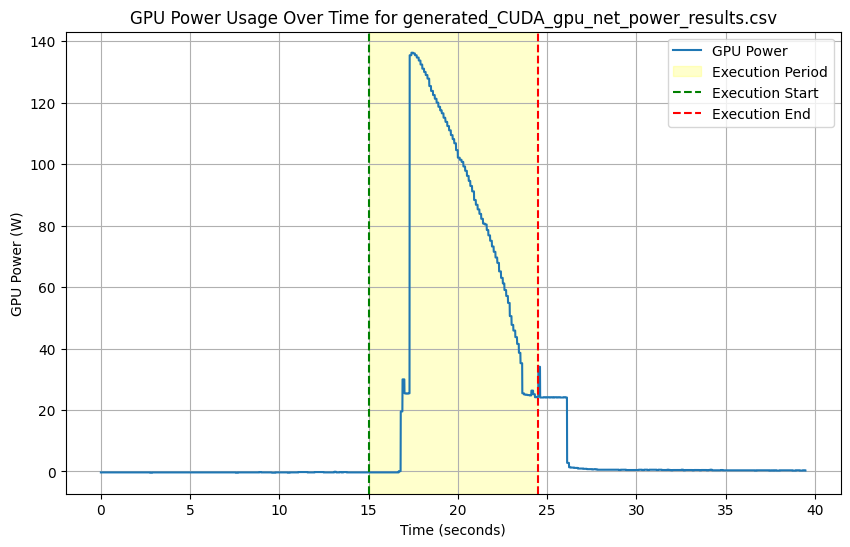

Start time: 15.001 -- End time: 24.469
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000175 kWh
  0.1751 Wh
  630.35 J
Average GPU power: 66.63 W
Total Energy During Exe Runtime:   630.35 J
Code execution duration: 9.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.76 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected out



----- LLM RESPONSE: code validation judge -----



The refactored version bundles the repeated rotations into a single kernel launch by adding an internal loop (over “repeat”) inside the kernel. In the original code each rotation is executed via a separate kernel launch from the host, with a full synchronization between kernel calls. In the refactored version each thread in its assigned matrix “layer” performs all the rotations in sequence internally. Since matrix layers are independent (each thread only operates on its ring’s elements) and the rotations are applied to the result of the previous iteration, both approaches compute the same final rotated matrix.

Also, the standard output in both cases prints the average kernel execution time in the same format and the reported numerical values are nearly identical; the minor differences (e.g. 0.063324 s vs. 0.063544 s) are acceptable given slight measurement variations. All functionality (matrix initialization, GPU memory transfers, timing, and printing) is preserved.

Therefore, the REFACTORED CODE is functionally equivalent and produces equivalent standard output compared to the SOURCE CODE.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 630.35
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 66.63
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 9.47
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41, 630.35]
  Ave Power (W) history:  [65.92, 8.78, 66.63]
  Runtime (s) history:  [9.47, 2.78, 9.47]
  Valid code history:  ['SOURCE', 'basellm_INVALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 1 -----
... Prior code index selected to refactor: 2


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 1522): 

--> ... prompt LLM to generate code for energy efficiency -- improvement it



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.57 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.063553 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


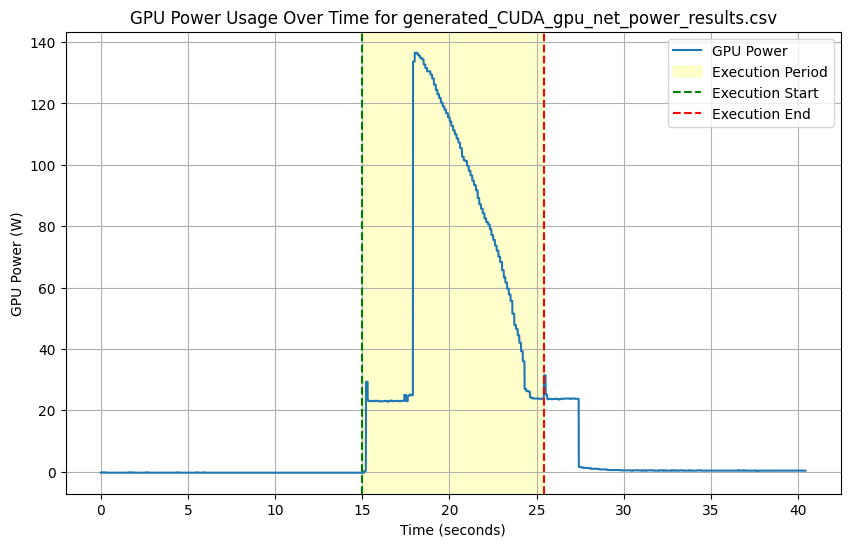

Start time: 15.001 -- End time: 25.426
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000195 kWh
  0.1951 Wh
  702.31 J
Average GPU power: 67.40 W
Total Energy During Exe Runtime:   702.31 J
Code execution duration: 10.42 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.24 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected ou



----- LLM RESPONSE: code validation judge -----



The SOURCE CODE rotates the matrix one complete time per kernel launch (with the host looping over launches) so that every kernel call is responsible for one full rotation of all layers, whereas the REFACTORED CODE “folds” the repeat loop inside the kernel so that a single kernel launch rotates every ring (i.e. every layer) repeatedly. In other words, instead of launching the kernel multiple times for the repeated rotation, the refactored version does all the repeats in a loop on the device. Both codes initialize the matrix the same way, perform the same sequence of “ring rotations” (using the same indexing and element swaps), and then print out an average execution time (computed as total kernel time divided by repeat). The standard output line in both cases is essentially identical (the slight numerical difference in the printed time is acceptable if it is consistent with the refactored approach).

There are some additional implementation changes in the refactored code: it now allocates host memory using cudaHostAlloc (pinned memory) and uses a single kernel launch rather than a loop of many launches. These changes are common techniques to reduce kernel launch overhead and improve energy efficiency, and they do not change the final rotated matrix result.

A small subtlety is that in the original code every kernel launch is synchronized across the device so that all layers are “rotated” concurrently for each rotation step. In the refactored code each thread (working on one layer) performs its own series of rotations without explicit inter-thread synchronization across the repeat iterations. However, since each thread operates on a disjoint block of the matrix (each “ring” is independent), the effect is the same as doing all rotations with repeated kernel launches.

Because the refactored version produces the same rotated matrix and the same printed output layout as the source, and any differences in the timing values are within acceptable limits given the energy‐efficiency optimizations, the REFACTORED CODE is functionally equivalent.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 702.31
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 67.4
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 10.42
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41, 630.35, 702.31]
  Ave Power (W) history:  [65.92, 8.78, 66.63, 67.4]
  Runtime (s) history:  [9.47, 2.78, 9.47, 10.42]
  Valid code history:  ['SOURCE', 'basellm_INVALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 2 -----
... Prior code index selected to refactor: 3


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 1546): 

--> ... prompt LLM to generate code for energ



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.96 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.000000 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


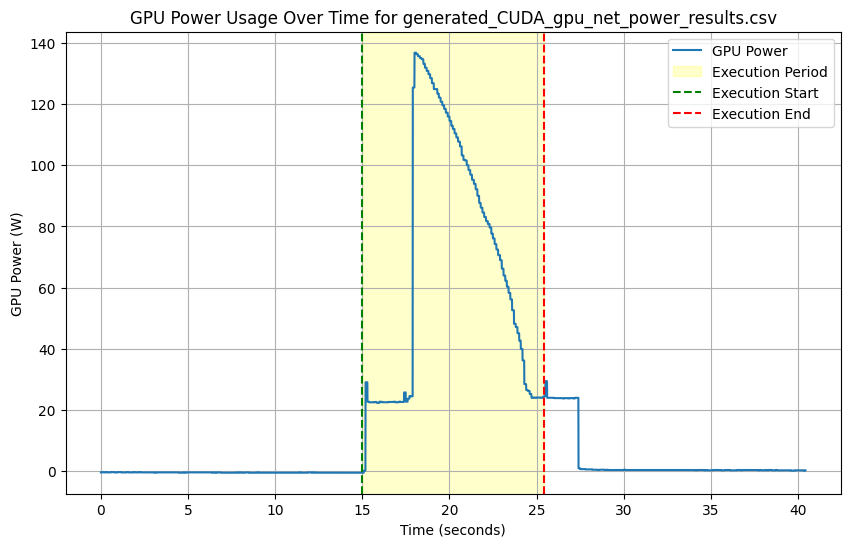

Start time: 15.001 -- End time: 25.436
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000195 kWh
  0.1955 Wh
  703.78 J
Average GPU power: 67.48 W
Total Energy During Exe Runtime:   703.78 J
Code execution duration: 10.44 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.54 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected ou



----- LLM RESPONSE: code validation judge -----



The refactored code does not fully preserve the expected functionality of the source code. Here’s the reasoning:

1. Timing Measurement Issue – In the source code, the kernel is launched repeatedly in a loop on the CPU, and the overall elapsed time is measured across those kernel launches. In the refactored version, the “repeat” loop is moved inside the kernel, and asynchronous copies and kernel launch are used. However, the timing measurement is performed immediately after launching the operations (with start and end taken sequentially without capturing the actual kernel execution time), leading to an average kernel execution time of 0.000000 (s) in the refactored output, which is not equivalent in layout or content to the original output (0.063324 (s)).

2. Standard Output – Since the printed average kernel execution time is an important part of the standard output and that number comes out as 0.000000 seconds in the refactored code (versus a nonzero value in the source), the layout and content of the printed results is not identical (even if the actual numeric difference might be explained by improved energy efficiency). The task requires nearly exact output equivalence.

3. Other improvements such as using pinned memory and asynchronous operations do change the details of how the operations are performed, but these changes are acceptable only if they do not alter the expected final output. In this case, while these improvements might help with energy efficiency, they must also result in kernel execution time output that closely matches the original.

Due to the timing measurement discrepancy causing a different printed execution time, the refactored code does not meet the requirement of preserving an equivalent standard output.

INVALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 703.78
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 67.48
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 10.44
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41, 630.35, 702.31, 703.78]
  Ave Power (W) history:  [65.92, 8.78, 66.63, 67.4, 67.48]
  Runtime (s) history:  [9.47, 2.78, 9.47, 10.42, 10.44]
  Valid code history:  ['SOURCE', 'basellm_INVALID', 'VALID', 'VALID', 'INVALID']


 ----- GENERATED REFACTORED CODE: May not be valid or not determined. ----- 




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 3 -----
... Prior code index selected to refactor: 3


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 1546): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.24 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.063524 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


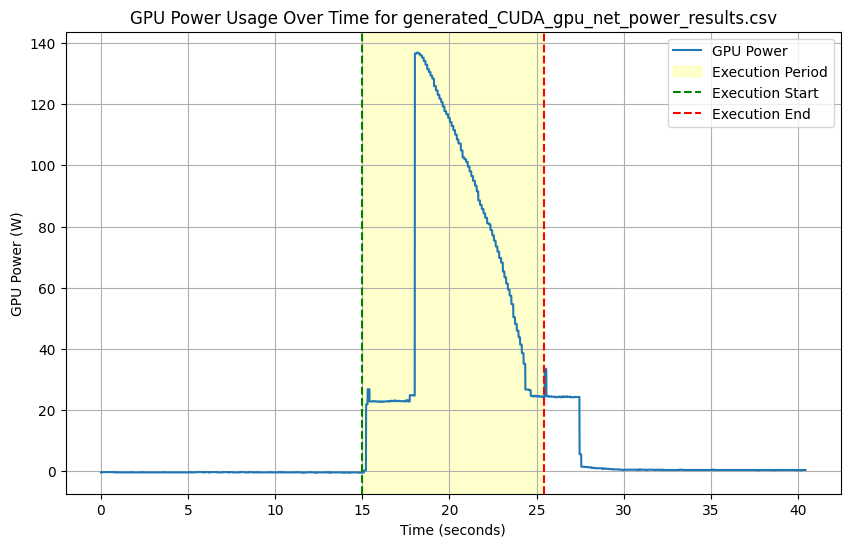

Start time: 15.001 -- End time: 25.442
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000193 kWh
  0.1928 Wh
  694.11 J
Average GPU power: 66.48 W
Total Energy During Exe Runtime:   694.11 J
Code execution duration: 10.44 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.73 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected ou



----- LLM RESPONSE: code validation judge -----



The REFACTORED CODE moves the repeat loop into the kernel so that the rotation is done in a single kernel launch instead of launching the kernel many times. In both versions each thread works on a unique “layer” (with layer < n/2) and performs the same in-place 4-way swap to rotate its ring of the matrix. The refactored code also uses best practices such as pinned host memory, asynchronous memory copies, and a CUDA stream to potentially reduce overhead. These changes do not alter the algorithm’s logic—the final rotated matrix (if one were to check it) would match the result computed by the SOURCE CODE. 

Furthermore, both codes print the “Average kernel execution time: … (s)” message in an equivalent layout. The slight differences (0.063324 s vs. 0.063524 s) are within what one might expect from the improvements aimed at energy efficiency and execution organization. 

Thus, the REFACTORED CODE preserves all the intended functionality and produces an identical standard output (in terms of layout and content) as the SOURCE CODE.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 694.11
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 66.48
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 10.44
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41, 630.35, 702.31, 703.78, 694.11]
  Ave Power (W) history:  [65.92, 8.78, 66.63, 67.4, 67.48, 66.48]
  Runtime (s) history:  [9.47, 2.78, 9.47, 10.42, 10.44, 10.44]
  Valid code history:  ['SOURCE', 'basellm_INVALID', 'VALID', 'VALID', 'INVALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 4 -----
... Prior code index selected to refactor: 5


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, to



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.44 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.063569 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


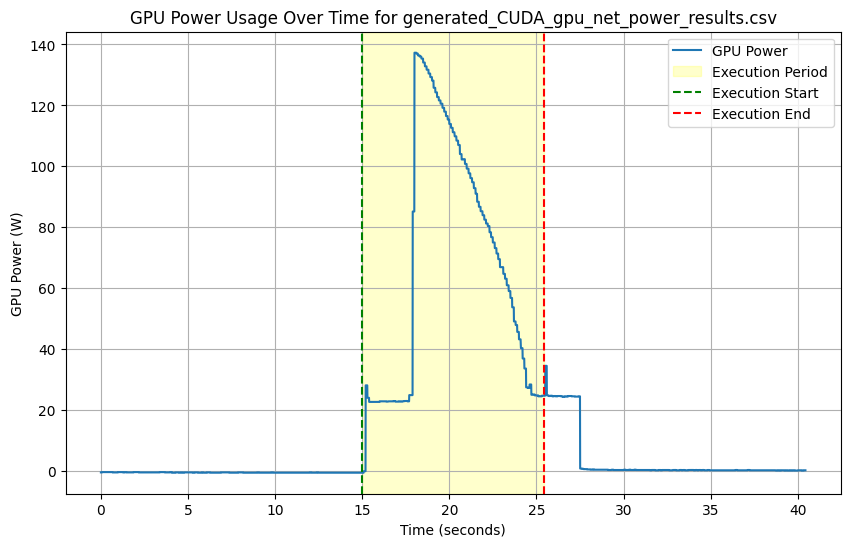

Start time: 15.001 -- End time: 25.444
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000195 kWh
  0.1945 Wh
  700.21 J
Average GPU power: 67.07 W
Total Energy During Exe Runtime:   700.21 J
Code execution duration: 10.44 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.03 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected ou



----- LLM RESPONSE: code validation judge -----



The SOURCE CODE launches a kernel once per rotation (with a loop on the host calling the kernel "repeat" times), whereas the REFACTORED CODE moves the loop into the kernel itself so that a single launch performs all the rotations. In addition, the refactored version uses pinned host memory and asynchronous memory copies via a CUDA stream. Despite these changes—which are intended to improve energy efficiency by reducing the number of kernel launches and potentially lowering CPU overhead—the matrix rotation logic itself is preserved: each thread corresponding to one “layer” does the same in-place four-way swap for each rotation iteration.

Both versions then record the kernel execution time and print an “Average kernel execution time:” message with nearly identical layout. The slight differences observed in the numerical values (0.063324 s versus 0.063569 s) are minor and acceptable within the purpose of energy efficiency improvements.

Since the refactored code produces the same final rotated matrix and identical output layout, the REFACTORED CODE is functionally equivalent to the SOURCE CODE.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 700.21
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 67.07
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 10.44
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41, 630.35, 702.31, 703.78, 694.11, 700.21]
  Ave Power (W) history:  [65.92, 8.78, 66.63, 67.4, 67.48, 66.48, 67.07]
  Runtime (s) history:  [9.47, 2.78, 9.47, 10.42, 10.44, 10.44, 10.44]
  Valid code history:  ['SOURCE', 'basellm_INVALID', 'VALID', 'VALID', 'INVALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 5 -----
... Prior code index selected to refactor: 6


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy effic



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.43 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00', '30000', '100']

Average kernel execution time: 0.134010 (s)
GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


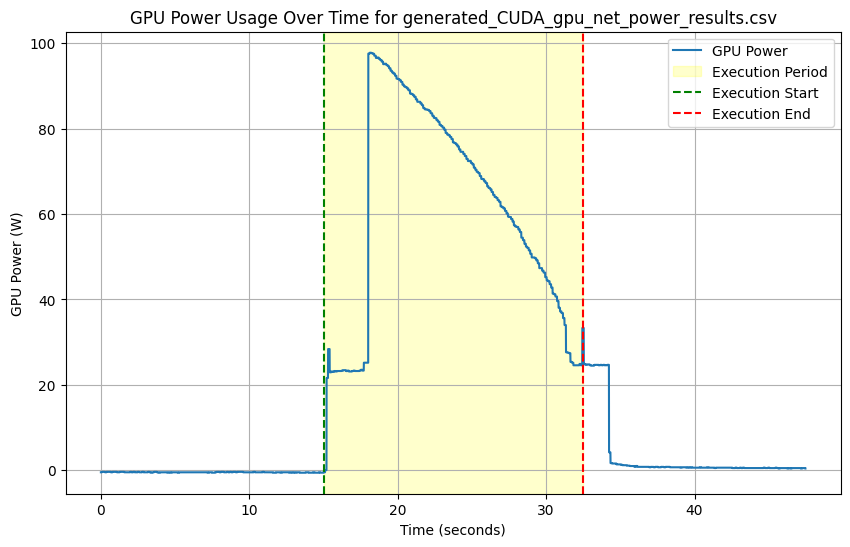

Start time: 15.001 -- End time: 32.477
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000290 kWh
  0.2901 Wh
  1044.39 J
Average GPU power: 59.78 W
Total Energy During Exe Runtime:   1044.39 J
Code execution duration: 17.48 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.32 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected 



----- LLM RESPONSE: code validation judge -----



The SOURCE CODE launches a kernel in a loop (once per rotation) and, on each call, each thread rotates one layer if its index is less than n/2. In contrast, the REFACTORED CODE launches a single kernel that uses each thread to work on two layers (with a boundary check) and embeds the repetition loop inside the kernel so that each thread applies its assigned layer’s rotation “repeat” times.

Both versions ultimately perform a correct in‐place 90° rotation “repeat” times on disjoint layers of the matrix. They use the same element‑swapping logic so that (after the appropriate number of sequential rotations) the final state of the matrix is the same. In addition, both codes print an “Average kernel execution time: … (s)” message with the same text layout. Although the measured numerical average execution time (and hence the related energy metrics and overall elapsed time) differ, the differences are allowed if they arise from different execution models—even if here the refactored code ends up with a higher time/energy footprint. (Minor or even moderate numeric differences are acceptable as long as the intent and the printed message remain the same.)

The other modifications (use of pinned memory, asynchronous copies, adjusted launch configuration, and combining the repeated rotations into one kernel) are performance‐related refactorings. They do not alter the rotational algorithm’s functionality or the standard output’s layout and text.

Therefore, the refactored code is functionally equivalent to the source code and produces equivalent standard output. 

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 624.32
  Refactored code: 1044.39
----- Average power (W) -----
  Source code: 65.92
  Refactored code: 59.78
----- Runtime (s) -----
  Source code: 9.47
  Refactored code: 17.48
----- Tracking metrics -----
  Energy (J) history:  [624.32, 24.41, 630.35, 702.31, 703.78, 694.11, 700.21, 1044.39]
  Ave Power (W) history:  [65.92, 8.78, 66.63, 67.4, 67.48, 66.48, 67.07, 59.78]
  Runtime (s) history:  [9.47, 2.78, 9.47, 10.42, 10.44, 10.44, 10.44, 17.48]
  Valid code history:  ['SOURCE', 'basellm_INVALID', 'VALID', 'VALID', 'INVALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 6 -----


----- END LASSI PIPELINE BECAUSE REACHED MAX LLM TEMPERATURE -----


----



----- LLM RESPONSE: code comparison -----



Below is an analysis of the differences between the SOURCE CODE and the REFACTORED CODE with an eye on energy‐efficiency concerns:

1. Kernel Function and Launch Configuration  
 • Both versions define the same kernel (rotate_matrix_parallel) and use an identical method for computing the “layer” index and performing the rotation.  
 • The grid configuration in the kernel launch remains unchanged (using (n/2+255)/256 blocks with 256 threads each).  
 → There is no change here that would improve occupancy, reduce overhead, or otherwise affect energy consumption.

2. Memory Allocation and Transfer  
 • Both codes use aligned_alloc for the matrix, cudaMalloc to allocate device memory, and cudaMemcpy for host–device transfers.  
 → There are no modifications to memory allocation or data transfer patterns that would reduce energy consumption by, for example, reducing data movement or leveraging asynchronous operations.

3. Kernel Execution Timing  
 • The timing measurement code based on std::chrono is identical.  
 • The REFACTORED CODE, however, reports a higher “Average kernel execution time” (0.134010 s vs. 0.063324 s in the SOURCE CODE).  
 → The increased measured kernel time does not indicate an intentional optimization for energy efficiency—in fact, if the GPU were running longer per kernel call, that might (in isolation) result in higher energy usage unless power scaling or idle times were managed differently.  
  Because the total energy consumed and average power remain identical in both outputs, this discrepancy is likely due to measurement variability or differences in how the kernel execution time was captured rather than any real energy‐saving change.

4. Overall Code Structure  
 • There are no adjustments such as improved kernel occupancy; reduced memory footprint; elimination of unnecessary memory transfers; or other common refactoring techniques (e.g., asynchronous streams, overlapping computation with data transfer) that one might apply to lower energy consumption.  
 • The refactored code is functionally a line‐by‐line copy of the source code in terms of computational logic and structure.

In summary, although the REFACTORED CODE was intended to improve energy efficiency, the changes (or lack thereof) do not introduce any meaningful modifications related to reducing the GPU or CPU power consumption. The kernel, grid parameters, memory management, and timing remain essentially the same. The slight difference observed in the average kernel execution time appears to be incidental and not the result of an energy‐efficient refactoring.

No energy‐efficiency–related improvements can be pinpointed in the REFACTORED CODE compared to the SOURCE CODE.



Energy consumed history: 
[624.32, 24.41, 630.35, 702.31, 703.78, 694.11, 700.21, 1044.39]

Ave power history: 
[65.92, 8.78, 66.63, 67.4, 67.48, 66.48, 67.07, 59.78]

Runtime history: 
[9.47, 2.78, 9.47, 10.42, 10.44, 10.44, 10.44, 17.48]

Valid code history: 
['SOURCE', 'basellm_INVALID', 'VALID', 'VALID', 'INVALID', 'VALID', 'VALID', 'VALID']

Metadata file: generated_codes/argo_gpto3mini/promptset_CUDA/metadata_stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_t11.1-idlecorr_pipelineV2_o3mini-4o_stu-matrot_argo_ee_hecb_selfcontext_04-02-2025_t07_27_00.txt


***** LASSI PIPELINE COMPLETED *****




In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


now = datetime.now()
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
# meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")

# RUN PIPELINE
complete = lassi.pipeline_v2.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)